<a href="https://colab.research.google.com/github/hemant-rawani9/HorizonTechX-Task-Data-Science/blob/main/TASK_3_Car_Price_Prediction_using_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Search for Local Datasets
We will list files in the current workspace directory to check if a car dataset has been uploaded.

In [6]:
import os
import glob

# Search for any CSV files in the workspace
csv_files = glob.glob('*.csv')
print("Found CSV files:", csv_files)

Found CSV files: []


### Step 2: Load or Generate Dataset
If a CSV file is present, we will load it. Otherwise, we will generate a high-quality synthetic dataset of car specifications and prices so you have a fully working end-to-end pipeline immediately.

In [7]:
import pandas as pd
import numpy as np

# If a CSV was found, load the first one. Otherwise, create a synthetic one.
if csv_files:
    file_path = csv_files[0]
    print(f"Loading dataset: {file_path}")
    df = pd.read_csv(file_path)
else:
    print("No local CSV found. Generating a realistic synthetic car dataset...")
    np.random.seed(42)
    n_samples = 1000

    brands = ['Toyota', 'Honda', 'Ford', 'BMW', 'Mercedes', 'Hyundai', 'Audi']
    fuel_types = ['Petrol', 'Diesel', 'Hybrid', 'Electric']

    synthetic_brands = np.random.choice(brands, n_samples)
    synthetic_mileage = np.random.randint(5000, 150000, n_samples)
    synthetic_engine_power = np.random.randint(80, 450, n_samples)
    synthetic_fuel = np.random.choice(fuel_types, n_samples, p=[0.5, 0.3, 0.15, 0.05])
    synthetic_age = np.random.randint(1, 15, n_samples)

    # Establish a realistic base pricing formula + noise
    brand_multiplier = {'Toyota': 1.0, 'Honda': 1.1, 'Ford': 0.9, 'BMW': 1.8, 'Mercedes': 2.0, 'Hyundai': 0.85, 'Audi': 1.7}
    base_price = 20000

    prices = []
    for i in range(n_samples):
        price = (base_price
                 + (synthetic_engine_power[i] * 120)
                 - (synthetic_mileage[i] * 0.08)
                 - (synthetic_age[i] * 1000))
        price *= brand_multiplier[synthetic_brands[i]]
        # Add adjustments for fuel type
        if synthetic_fuel[i] == 'Electric':
            price += 8000
        elif synthetic_fuel[i] == 'Hybrid':
            price += 3000
        # Add random noise
        price += np.random.normal(0, 3000)
        # Ensure price is positive and realistic
        prices.append(max(3000, round(price, 2)))

    df = pd.DataFrame({
        'Brand': synthetic_brands,
        'Mileage': synthetic_mileage,
        'Engine_Power_HP': synthetic_engine_power,
        'Fuel_Type': synthetic_fuel,
        'Age_Years': synthetic_age,
        'Price_USD': prices
    })

display(df.head())
display(df.describe())

No local CSV found. Generating a realistic synthetic car dataset...


,Brand,Mileage,Engine_Power_HP,Fuel_Type,Age_Years,Price_USD
0,Audi,75390,292,Petrol,5,72590.78
1,BMW,48088,222,Petrol,4,74809.74
2,Mercedes,108196,144,Petrol,14,31242.78
3,Audi,60479,155,Petrol,10,40667.76
4,Ford,24963,278,Petrol,1,44784.31


,Mileage,Engine_Power_HP,Age_Years,Price_USD
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,79959.756000,259.928000,7.655000,50922.492440
std,42213.625117,103.754652,4.043554,25935.103153
min,5126.000000,80.000000,1.000000,3000.000000
25%,43844.750000,176.000000,4.000000,31380.252500
50%,80656.000000,252.000000,8.000000,45936.945000
75%,117345.000000,348.000000,11.000000,65704.590000
max,149991.000000,449.000000,14.000000,136082.420000


### Step 3: Data Preprocessing & Exploratory Data Analysis (EDA)
We will handle categorical variables (One-Hot Encoding) and check correlations using visualizations.

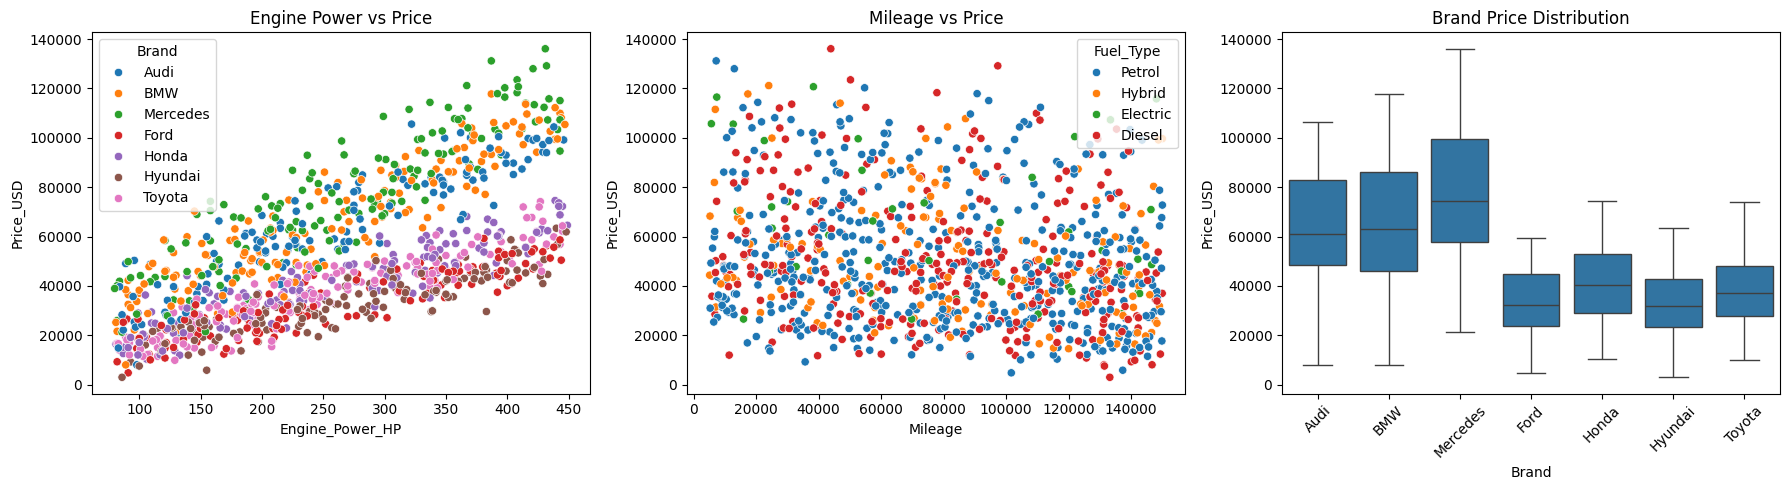

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize relations between features and price
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='Engine_Power_HP', y='Price_USD', hue='Brand', ax=axes[0])
axes[0].set_title('Engine Power vs Price')

sns.scatterplot(data=df, x='Mileage', y='Price_USD', hue='Fuel_Type', ax=axes[1])
axes[1].set_title('Mileage vs Price')

sns.boxplot(data=df, x='Brand', y='Price_USD', ax=axes[2])
axes[2].set_title('Brand Price Distribution')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Step 4: Feature Engineering & Model Training
We will encode the categorical features and train a `RandomForestRegressor` and a `LinearRegression` model using Scikit-learn.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define target and features
X = df.drop(columns=['Price_USD'])
y = df['Price_USD']

# Identify categorical and numerical columns
categorical_features = ['Brand', 'Fuel_Type']
numerical_features = ['Mileage', 'Engine_Power_HP', 'Age_Years']

# Setup preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ])

# Create a pipeline for Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Create a pipeline for Linear Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train models
rf_pipeline.fit(X_train, y_train)
lr_pipeline.fit(X_train, y_train)

print("Models successfully trained!")

Models successfully trained!


### Step 5: Model Evaluation
Let's evaluate the performance of both models using $R^2$, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

In [10]:
def evaluate_model(model, name):
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    print(f"=== {name} Performance ===")
    print(f"Mean Absolute Error: ${mae:.2f}")
    print(f"Root Mean Squared Error: ${rmse:.2f}")
    print(f"R² Score: {r2:.4f}\n")
    return predictions

y_pred_rf = evaluate_model(rf_pipeline, "Random Forest Regressor")
y_pred_lr = evaluate_model(lr_pipeline, "Linear Regression")

=== Random Forest Regressor Performance ===
Mean Absolute Error: $4834.18
Root Mean Squared Error: $5999.92
R² Score: 0.9468

=== Linear Regression Performance ===
Mean Absolute Error: $5243.37
Root Mean Squared Error: $6312.13
R² Score: 0.9411



### Step 6: Real-World Applications of Car Price Prediction Models

Automated valuation and regression-based price prediction models are widely used across the automotive and financial industries:

1. **Dynamic Pricing for Dealerships & E-commerce Platforms**
   - Online marketplaces (e.g., Carvana, AutoTrader, CoPilot) use predictive models to instantly appraise trade-in vehicles and suggest retail list prices that maximize profit margin while minimizing days-on-market.

2. **Fleet Management and Depreciation Analysis**
   - Rental car agencies (like Hertz, Enterprise) and corporate fleet managers track the projected future values of their vehicles to optimize the optimal time to retire and sell assets before depreciation curves steepen.

3. **Financial Underwriting & Insurance**
   - Banks and lending institutions use valuation models to verify collateral values when issuing auto loans.
   - Insurance companies utilize these predictions to determine the Actual Cash Value (ACV) of vehicles for underwriting policy premiums and settling total-loss claims.

4. **Algorithmic Arbitrage for Smart Buyers & Flippers**
   - Real-world buyers use predictive boundaries to identify underpriced vehicles (where `Actual Price < Predicted Price`) on public listings, allowing for profitable arbitrage or negotiating power.